# Step 2b: Descriptive statistics

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

This notebook summarises the cleaned dataset (task 2 of the assignment). Describing the data comes before predicting or detecting anything (Introduction, Slide 19, describing versus predicting). It answers:

1. What does the dataset contain, and how are the main variables distributed?
2. How does demand vary with season, weekday, hour and weather?
3. How do casual and registered riders differ?
4. Which weather variables go together with demand, and which are redundant?

**Inputs:** `hour_clean.csv` (Step 1), `day_info.csv`, `day_matrix_casual.csv`, `day_matrix_registered.csv` (Step 2).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

hour = pd.read_csv("hour_clean.csv", parse_dates=["dteday"])
day = pd.read_csv("day_info.csv", index_col="dteday", parse_dates=True)
day["casual"] = pd.read_csv("day_matrix_casual.csv", index_col="dteday", parse_dates=True).sum(axis=1)
day["registered"] = pd.read_csv("day_matrix_registered.csv", index_col="dteday", parse_dates=True).sum(axis=1)

SEASONS = {1: "winter", 2: "spring", 3: "summer", 4: "autumn"}
WEEKDAYS = {0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"}
WEATHER = {1: "clear", 2: "mist", 3: "rain or snow"}

## 1. What the dataset contains

In [2]:
print(f"Period: {day.index.min():%d %b %Y} to {day.index.max():%d %b %Y} ({len(day)} days, {len(hour):,} hours after cleaning)")
print(f"Total rentals: {day.total.sum():,}  (casual {day.casual.sum():,}, registered {day.registered.sum():,})")
print(f"Casual share of all rentals: {day.casual.sum() / day.total.sum():.1%}")

pd.DataFrame({
    "variable": ["cnt / total", "casual", "registered", "temperature", "feels-like temperature", "humidity",
                 "wind speed", "weather situation", "season, month, weekday", "holiday, working day"],
    "type": ["count", "count", "count", "numeric", "numeric", "numeric", "numeric", "ordinal (1 to 3 after cleaning)",
             "categorical", "binary"],
    "unit or values": ["rentals per hour / day", "rentals", "rentals", "°C", "°C", "%", "km/h",
                       "1 clear, 2 mist, 3 rain or snow", "calendar", "0 or 1"],
}).set_index("variable")

Period: 01 Jan 2011 to 31 Dec 2012 (731 days, 17,544 hours after cleaning)
Total rentals: 3,292,679  (casual 620,017, registered 2,672,662)
Casual share of all rentals: 18.8%


,type,unit or values
variable,,
cnt / total,count,rentals per hour / day
casual,count,rentals
registered,count,rentals
temperature,numeric,°C
feels-like temperature,numeric,°C
humidity,numeric,%
wind speed,numeric,km/h
weather situation,ordinal (1 to 3 after cleaning),"1 clear, 2 mist, 3 rain or snow"
"season, month, weekday",categorical,calendar


## 2. Summary statistics

Daily values (one row per day). Skewness measures asymmetry: 0 is symmetric, positive means a long tail of high values.

In [3]:
cols = {"total": "Total rentals per day", "casual": "Casual rentals per day", "registered": "Registered rentals per day",
        "temp_c_mean": "Mean temperature (°C)", "hum_pct_mean": "Mean humidity (%)", "wind_kmh_mean": "Mean wind speed (km/h)"}
summary = day[list(cols)].describe().T
summary["skewness"] = day[list(cols)].skew()
summary.index = summary.index.map(cols)
summary.drop(columns="count").round(1)

,mean,std,min,25%,50%,75%,max,skewness
Total rentals per day,4504.3,1937.2,22.0,3152.0,4548.0,5956.0,8714.0,-0.0
Casual rentals per day,848.2,686.6,2.0,315.5,713.0,1096.0,3410.0,1.3
Registered rentals per day,3656.2,1560.3,20.0,2497.0,3662.0,4776.5,6946.0,0.0
Mean temperature (°C),15.3,8.6,-5.3,7.8,15.4,22.8,32.5,-0.1
Mean humidity (%),62.9,14.0,18.8,52.2,62.9,73.0,97.2,0.0
Mean wind speed (km/h),12.8,5.2,1.5,9.0,12.1,15.7,34.0,0.7


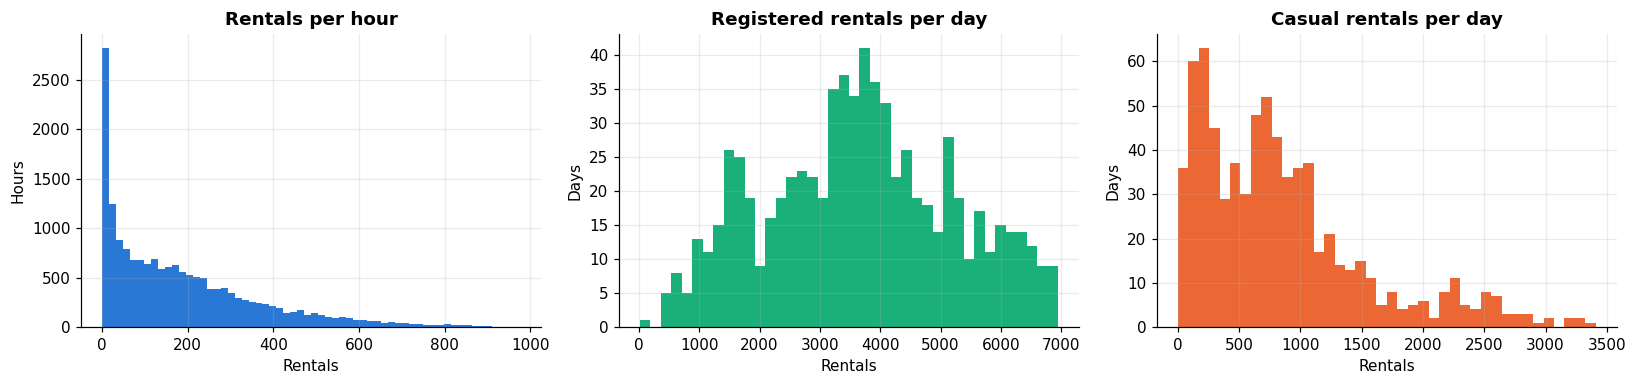

Skewness: hourly cnt 1.28, daily registered 0.04, daily casual 1.27


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(hour.cnt, bins=60, color=BLUE)
axes[0].set(title="Rentals per hour", xlabel="Rentals", ylabel="Hours")
axes[1].hist(day.registered, bins=40, color=AQUA)
axes[1].set(title="Registered rentals per day", xlabel="Rentals", ylabel="Days")
axes[2].hist(day.casual, bins=40, color=ORANGE)
axes[2].set(title="Casual rentals per day", xlabel="Rentals", ylabel="Days")
fig.tight_layout()
plt.show()
print(f"Skewness: hourly cnt {hour.cnt.skew():.2f}, daily registered {day.registered.skew():.2f}, daily casual {day.casual.skew():.2f}")

**Result.**

- **Hourly counts are strongly right-skewed** (skewness about 1.3): most hours are quiet and a few rush hours are very busy. The mean (about 190 per hour) is well above the median (140), so the median is the better "typical hour". This is why later steps use medians and robust spreads.
- **Daily registered rentals are roughly symmetric**, while **daily casual rentals are right-skewed**: most days have a few hundred casual rentals, and a small number of busy days (warm weekends) have several thousand.

## 3. How demand varies

### 3a. By season, year, day type and weather

In [5]:
def by(col, mapping=None):
    t = day.groupby(col).agg(days=("total", "size"), mean=("total", "mean"), median=("total", "median"),
                             casual=("casual", "mean"), registered=("registered", "mean")).round(0)
    if mapping:
        t.index = t.index.map(mapping)
    return t

display(by("season", SEASONS).rename_axis("season"))
display(by("yr", {0: 2011, 1: 2012}).rename_axis("year"))
display(by("workingday", {0: "weekend or holiday", 1: "working day"}).rename_axis("day type"))
display(by("weathersit_worst", WEATHER).rename_axis("worst weather of the day"))

,days,mean,median,casual,registered
season,,,,,
winter,181,2604.0,2209.0,335.0,2269.0
spring,184,4992.0,4942.0,1106.0,3886.0
summer,188,5644.0,5354.0,1203.0,4442.0
autumn,178,4728.0,4634.0,729.0,3999.0


,days,mean,median,casual,registered
year,,,,,
2011,365,3406.0,3740.0,677.0,2728.0
2012,366,5600.0,5927.0,1018.0,4581.0


,days,mean,median,casual,registered
day type,,,,,
weekend or holiday,231,4330.0,4459.0,1371.0,2959.0
working day,500,4585.0,4582.0,607.0,3978.0


,days,mean,median,casual,registered
worst weather of the day,,,,,
clear,150,5033.0,4942.0,1014.0,4018.0
mist,278,4788.0,4766.0,928.0,3859.0
rain or snow,303,3983.0,4094.0,693.0,3290.0


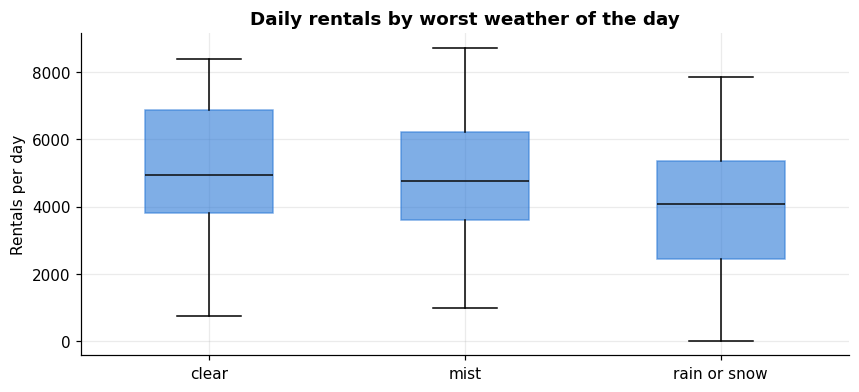

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
data = [day.total[day.weathersit_worst == w] for w in WEATHER]
bp = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops=dict(color="#0b0b0b"))
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE, alpha=0.6, edgecolor=BLUE)
ax.set(title="Daily rentals by worst weather of the day", xticks=[1, 2, 3], xticklabels=list(WEATHER.values()),
       ylabel="Rentals per day")
plt.show()

**Result.**

- **Season matters most:** summer averages more than twice as many rentals per day as winter.
- **2012 is much busier than 2011**, the growth found in Step 1.
- **Working days and days off have similar totals**, but very different riders (next section).
- **Weather lowers demand step by step:** days with some rain or snow have clearly lower rentals than clear days. The boxplot (Anomaly Detection 1, Slide 22) also shows that rainy days are much more spread out, with long tails of very low days; these are the storm days that the anomaly detection in Step 7 picks up.

### 3b. By weekday and by hour

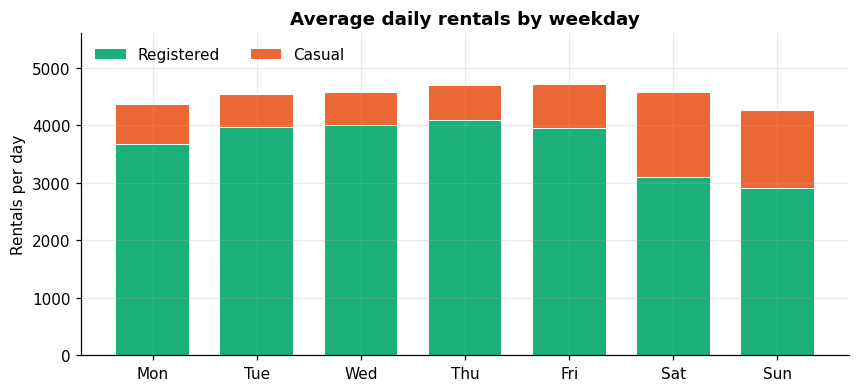

weekday,Mon,Tue,Wed,Thu,Fri,Sat,Sun
registered,3664.0,3954.0,3997.0,4076.0,3938.0,3085.0,2891.0
casual,674.0,556.0,551.0,591.0,752.0,1465.0,1338.0


In [7]:
weekday = day.groupby("weekday")[["registered", "casual"]].mean().rename(index=WEEKDAYS)
weekday = weekday.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(weekday.index, weekday.registered, color=AQUA, label="Registered", width=0.7)
ax.bar(weekday.index, weekday.casual, bottom=weekday.registered + 15, color=ORANGE, label="Casual", width=0.7)
ax.set(title="Average daily rentals by weekday", ylabel="Rentals per day", ylim=(0, 5600))
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()
weekday.round(0).T

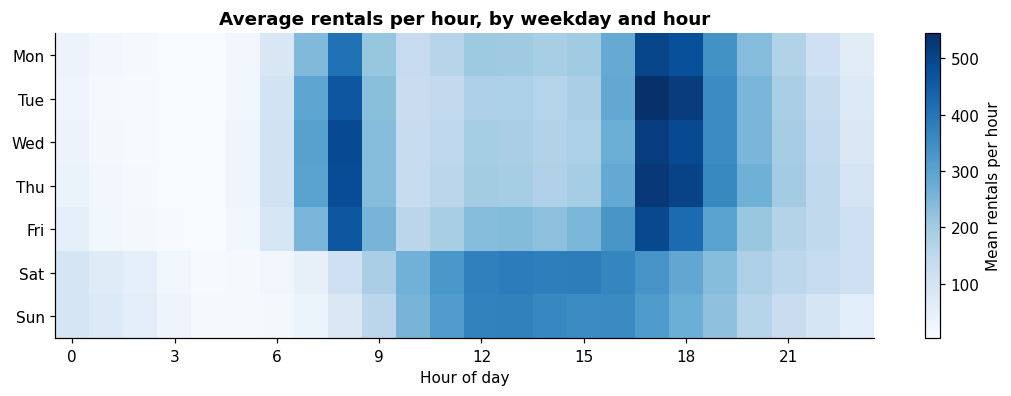

Busiest hour on average: 17:00 (461 rentals per hour)


In [8]:
grid = hour.assign(weekday=hour.weekday.map(WEEKDAYS)).pivot_table(index="weekday", columns="hr", values="cnt", aggfunc="mean")
grid = grid.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]

fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(grid.values, aspect="auto", cmap="Blues")
ax.set(title="Average rentals per hour, by weekday and hour", xlabel="Hour of day",
       xticks=range(0, 24, 3), yticks=range(7), yticklabels=grid.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Mean rentals per hour")
plt.show()
print(f"Busiest hour on average: {hour.groupby('hr').cnt.mean().idxmax()}:00 "
      f"({hour.groupby('hr').cnt.mean().max():.0f} rentals per hour)")

**Result.**

- **Casual and registered riders mirror each other over the week.** Casual riders more than double at weekends, while registered riders drop by about a quarter. The total looks flat across the week only because the two groups cancel out.
- **The hour-by-weekday heatmap** shows the commuting peaks at 8:00 and 17:00 to 18:00 from Monday to Friday, and one broad midday block on Saturday and Sunday. The busiest hour on average is 17:00.

## 4. Casual versus registered riders

In [9]:
share = pd.DataFrame({
    "casual share of rentals": [day.casual.sum() / day.total.sum(),
                                day.casual[day.workingday == 1].sum() / day.total[day.workingday == 1].sum(),
                                day.casual[day.workingday == 0].sum() / day.total[day.workingday == 0].sum()]},
    index=["all days", "working days", "weekends and holidays"])
display(share.style.format("{:.0%}"))
print(f"Correlation between daily casual and registered rentals: {day.casual.corr(day.registered):.2f}")

,casual share of rentals
all days,19%
working days,13%
weekends and holidays,32%


Correlation between daily casual and registered rentals: 0.40


**Result.** Casual riders make up about a fifth of all rentals, but about a third on weekends and holidays. Daily casual and registered totals are only moderately correlated (about 0.4): the two groups share the seasons and the weather, but respond very differently to the day of the week. This is the descriptive basis for analysing them separately (second research question).

## 5. Weather and demand: correlations

Two correlation measures are shown:

- **Pearson:** strength of a *straight-line* relationship;
- **Spearman:** strength of any relationship that only goes up (or only down), computed on ranks, so it is less affected by skewed variables and outliers.

In [10]:
weather = {"temp_c_mean": "temperature", "atemp_c_mean": "feels-like temperature",
           "hum_pct_mean": "humidity", "wind_kmh_mean": "wind speed"}
targets = ["casual", "registered", "total"]
pearson = day[list(weather) + targets].corr().loc[list(weather), targets].rename(index=weather)
spearman = day[list(weather) + targets].corr("spearman").loc[list(weather), targets].rename(index=weather)
both = pd.concat({"Pearson": pearson, "Spearman": spearman}, axis=1).round(2)
display(both)
print(f"Correlation between temperature and feels-like temperature: {day.temp_c_mean.corr(day.atemp_c_mean):.3f}")

Pearson                  Spearman                 
                        casual registered total   casual registered total
temperature               0.54       0.54  0.63     0.67       0.53  0.62
feels-like temperature    0.55       0.55  0.64     0.67       0.54  0.63
humidity                 -0.09      -0.11 -0.12    -0.08      -0.10 -0.11
wind speed               -0.17      -0.23 -0.24    -0.19      -0.21 -0.23

Correlation between temperature and feels-like temperature: 0.997


**Result.**

- **Temperature is the weather variable most related to demand** (correlation about 0.5 to 0.6). With Spearman, the relation is **stronger for casual riders** (about 0.67) than for registered riders (about 0.53): casual demand rises steeply as it gets warmer, while commuters ride in most temperatures.
- **Humidity and wind** have only weak relationships with daily demand on their own.
- **Temperature and feels-like temperature are almost identical** (correlation about 0.997). Using both would count the same information twice, so later steps use temperature and keep feels-like temperature only for the feels-like gap feature (Step 6).

Correlation is not causation: temperature, season and daylight all rise together, so part of the temperature effect is also a season effect. This is why Step 3 compares days with similar nearby days instead of using raw totals.

## Summary for the report

- **731 days (2011 to 2012), 3.29 million rentals**, about 19% by casual riders.
- **Hourly counts are right-skewed**, so medians and robust statistics are used throughout.
- **Demand is highest in summer, lowest in winter** (more than double), and much higher in 2012 than in 2011.
- **Casual and registered riders mirror each other over the week:** casual riders more than double at weekends; registered riders peak on working days at 8:00 and 17:00 to 18:00.
- **Temperature is the strongest weather driver**, especially for casual riders; rain lowers demand and makes it far more variable; temperature and feels-like temperature are redundant.